# Task 2: Build, train and evaluate basic CNNs
## The objective of this task is to obtain highest possible accuracy on the validation set.

### task_2.ipynb - build, train, and evalute models on the pre split data

Adam Oakes

## Library Imports

In [2]:
import keras, pathlib
from keras import layers
from keras.utils import image_dataset_from_directory
from pathlib import Path
import matplotlib.pyplot as plt

## Using image_dataset_from_directory to read images from directories

In [3]:
image_size = (180, 180)
batch_size = 64
new_base_dir = pathlib.Path("images-split")
EPOCHS = 5

train_dataset = image_dataset_from_directory(
    new_base_dir / "train", image_size=image_size, batch_size=batch_size
)
validation_dataset = image_dataset_from_directory(
    new_base_dir / "validation", image_size=image_size, batch_size=batch_size
)
test_dataset = image_dataset_from_directory(
    new_base_dir / "test", image_size=image_size, batch_size=batch_size
)

Found 80000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.


## Instantiating a small ConvNet for REAL vs FAKE classification

In [4]:
inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1.0 / 255)(inputs)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=512, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model1 = keras.Model(inputs=inputs, outputs=outputs)

model1.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch.keras",
        save_best_only=True,
        monitor="val_loss",
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=3,
        mode='max',
        restore_best_weights=True
    )
]
history1 = model1.fit(
    train_dataset,
    epochs=EPOCHS,
    validation_data=validation_dataset,
    callbacks=callbacks,
)

Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 50s 34ms/step - accuracy: 0.8034 - loss: 0.4215 - val_accuracy: 0.8745 - val_loss: 0.3082
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 41s 33ms/step - accuracy: 0.8929 - loss: 0.2599 - val_accuracy: 0.8867 - val_loss: 0.2851
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 40s 32ms/step - accuracy: 0.9055 - loss: 0.2298 - val_accuracy: 0.9105 - val_loss: 0.2159
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 44s 36ms/step - accuracy: 0.9166 - loss: 0.2094 - val_accuracy: 0.9158 - val_loss: 0.2065
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 43s 34ms/step - accuracy: 0.9228 - loss: 0.1949 - val_accuracy: 0.9255 - val_loss: 0.1967


## Revise your architecture until you find the architecture that yields the highest accuracy on the validation set

### Use fewer epochs

In [5]:
#fewer epochs
inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1.0 / 255)(inputs)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=512, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model2 = keras.Model(inputs=inputs, outputs=outputs)

model2.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch.keras",
        save_best_only=True,
        monitor="val_loss",
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=3,
        mode='max',
        restore_best_weights=True
    )
]
history2 = model2.fit(
    train_dataset,
    epochs=4,
    validation_data=validation_dataset,
    callbacks=callbacks,
)

Epoch 1/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 48s 36ms/step - accuracy: 0.7849 - loss: 0.4527 - val_accuracy: 0.8689 - val_loss: 0.3029
Epoch 2/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 40s 32ms/step - accuracy: 0.8835 - loss: 0.2793 - val_accuracy: 0.8984 - val_loss: 0.2538
Epoch 3/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 40s 32ms/step - accuracy: 0.9098 - loss: 0.2243 - val_accuracy: 0.9079 - val_loss: 0.2327
Epoch 4/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 41s 32ms/step - accuracy: 0.9181 - loss: 0.2032 - val_accuracy: 0.9259 - val_loss: 0.1889


### Decrease filters

In [6]:
inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1.0 / 255)(inputs)
x = layers.Conv2D(filters=8, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=16, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model3 = keras.Model(inputs=inputs, outputs=outputs)

model3.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch.keras",
        save_best_only=True,
        monitor="val_loss",
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=3,
        mode='max',
        restore_best_weights=True
    )
]
history3 = model3.fit(
    train_dataset,
    epochs=4,
    validation_data=validation_dataset,
    callbacks=callbacks,
)

Epoch 1/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.7993 - loss: 0.4298 - val_accuracy: 0.8630 - val_loss: 0.3233
Epoch 2/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.8745 - loss: 0.3003 - val_accuracy: 0.8946 - val_loss: 0.2541
Epoch 3/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.8916 - loss: 0.2640 - val_accuracy: 0.9050 - val_loss: 0.2336
Epoch 4/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.9043 - loss: 0.2364 - val_accuracy: 0.8856 - val_loss: 0.2684


### Increase filters

In [7]:
inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1.0 / 255)(inputs)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=512, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=1024, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model4 = keras.Model(inputs=inputs, outputs=outputs)

model4.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch.keras",
        save_best_only=True,
        monitor="val_loss",
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=3,
        mode='max',
        restore_best_weights=True
    )
]
history4 = model4.fit(
    train_dataset,
    epochs=4,
    validation_data=validation_dataset,
    callbacks=callbacks,
)

Epoch 1/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 95s 71ms/step - accuracy: 0.8006 - loss: 0.4281 - val_accuracy: 0.8845 - val_loss: 0.2859
Epoch 2/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 83s 66ms/step - accuracy: 0.8919 - loss: 0.2643 - val_accuracy: 0.9108 - val_loss: 0.2186
Epoch 3/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 81s 65ms/step - accuracy: 0.9132 - loss: 0.2162 - val_accuracy: 0.9063 - val_loss: 0.2265
Epoch 4/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 86s 69ms/step - accuracy: 0.9233 - loss: 0.1944 - val_accuracy: 0.9265 - val_loss: 0.1867


### Decrease layers

In [8]:
inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1.0 / 255)(inputs)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model5 = keras.Model(inputs=inputs, outputs=outputs)

model5.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch.keras",
        save_best_only=True,
        monitor="val_loss",
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=3,
        mode='max',
        restore_best_weights=True
    )
]
history5 = model5.fit(
    train_dataset,
    epochs=4,
    validation_data=validation_dataset,
    callbacks=callbacks,
)

Epoch 1/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 41s 31ms/step - accuracy: 0.7669 - loss: 0.4835 - val_accuracy: 0.8127 - val_loss: 0.4108
Epoch 2/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 37s 30ms/step - accuracy: 0.8381 - loss: 0.3743 - val_accuracy: 0.8753 - val_loss: 0.3236
Epoch 3/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 37s 30ms/step - accuracy: 0.8788 - loss: 0.2950 - val_accuracy: 0.8873 - val_loss: 0.2816
Epoch 4/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 37s 30ms/step - accuracy: 0.8983 - loss: 0.2547 - val_accuracy: 0.9022 - val_loss: 0.2361


### Increase layer count

In [9]:
inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1.0 / 255)(inputs)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=512, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model6 = keras.Model(inputs=inputs, outputs=outputs)

model6.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch.keras",
        save_best_only=True,
        monitor="val_loss",
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=3,
        mode='max',
        restore_best_weights=True
    )
] callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch.keras",
        save_best_only=True,
        monitor="val_loss",
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=3,
        mode='max',
        restore_best_weights=True
    )
]
history6 = model6.fit(
    train_dataset,
    epochs=4,
    validation_data=validation_dataset,
    callbacks=callbacks,
)

Epoch 1/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 36s 25ms/step - accuracy: 0.8284 - loss: 0.3791 - val_accuracy: 0.8935 - val_loss: 0.2584
Epoch 2/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 30s 24ms/step - accuracy: 0.8999 - loss: 0.2458 - val_accuracy: 0.9130 - val_loss: 0.2188
Epoch 3/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 29s 23ms/step - accuracy: 0.9182 - loss: 0.2057 - val_accuracy: 0.9201 - val_loss: 0.2013
Epoch 4/4
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 29s 24ms/step - accuracy: 0.9287 - loss: 0.1804 - val_accuracy: 0.8979 - val_loss: 0.2592


##  Please study how the accuracy changes when the hyperparameters, such as, the number of filters, layers, etc., are increased and decreased.


In [10]:
print(history2.history["val_accuracy"][-1])
print(history3.history["val_accuracy"][-1])
print(history4.history["val_accuracy"][-1])
print(history5.history["val_accuracy"][-1])
print(history6.history["val_accuracy"][-1])

0.9258999824523926
0.8855999708175659
0.9265000224113464
0.9021999835968018
0.8978999853134155


In [11]:
print(model2.count_params())
print(model3.count_params())
print(model4.count_params())
print(model5.count_params())
print(model6.count_params())

1569089
98513
6271617
388673
1578337


#### Layers:
    - small - validation accuracy:0.90      parameter count: 388673
    - medium - validation accuracy:0.93     parameter count: 1569089
    - large - validation accuracy: 0.90     parameter count: 1578337

### Filters:
    - small - validation accuracy:0.88       parameter count: 98513
    - medium - validation accuracy:0.93       parameter count: 1569089
    - large - validation accuracy:0.93       parameter count: 6271617

Decreasing or increasing the layer or count from model 2 yielded poorer accuracy. Decreasing the filter count led to poorer accuracy. Increasing the filter count led to similar accuracy, at the cost of complexity.


# You should also plot your learning curves and include them in your report.

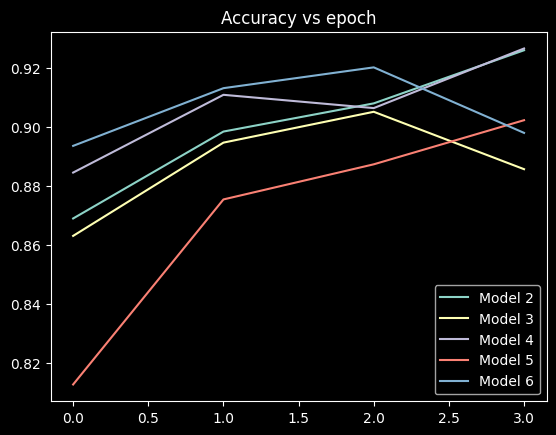

In [16]:
plt.title("Accuracy vs epoch")
plt.plot(history2.history["val_accuracy"], label="Model 2")
plt.plot(history3.history["val_accuracy"], label="Model 3")
plt.plot(history4.history["val_accuracy"], label="Model 4")
plt.plot(history5.history["val_accuracy"], label="Model 5")
plt.plot(history6.history["val_accuracy"], label="Model 6")

plt.legend()
fig = plt.gcf()
plt.show()
out = Path("task_2_photos")
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / "acc_vs_epoch.png")

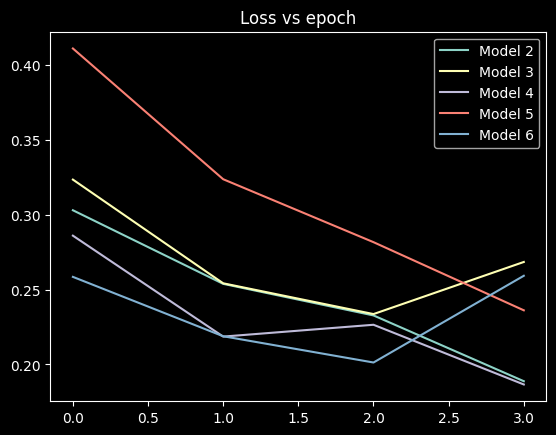

In [17]:
plt.title("Loss vs epoch")
plt.plot(history2.history["val_loss"], label="Model 2")
plt.plot(history3.history["val_loss"], label="Model 3")
plt.plot(history4.history["val_loss"], label="Model 4")
plt.plot(history5.history["val_loss"], label="Model 5")
plt.plot(history6.history["val_loss"], label="Model 6")

plt.legend()
fig = plt.gcf()
plt.show()
fig.savefig(out / "loss_vs_epoch.png")